<img src="https://cdn.jsdelivr.net/gh/maxischa/datacamp_test@bf9431e/ressources/img/logo_macmia.png" alt="Banque des Territoires · France 2030 · MACMIA" width="520">

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maxischa/datacamp_test/blob/main/bloc3_stats_v2/cours/seance1_cours.ipynb)

# Séance 3.1 — Décrire une distribution

**Cours** · durée : 4h (2h de cours, 2h d'exercices)

> ⚠️ **Avant de taper quoi que ce soit :** *Fichier → Enregistrer une copie dans Drive*. Sinon votre travail sera perdu en fermant l'onglet.
>
> 📱 Sur tablette, faites d'abord les réglages de [Bien démarrer](https://github.com/maxischa/datacamp_test/blob/main/ressources/setup_tablette.md).

## Objectifs

À la fin de cette séance, vous saurez :

- dire ce qu'une moyenne décrit — et ce qu'elle ne décrit pas
- choisir entre moyenne et médiane selon la forme de la distribution
- lire un `describe()` ligne par ligne
- mesurer la dispersion avec l'écart-type et l'écart interquartile
- repérer une concentration : quelle part du total tient dans le haut du classement
- décrire une variable qualitative — et savoir ce qu'on n'a pas le droit d'y calculer
- utiliser `groupby` pour calculer et comparer des statistiques entre plusieurs groupes
- utiliser `.agg()` pour calculer plusieurs indicateurs par groupe

## Une phrase de rapport, et le problème

> *« Le panier moyen de nos clients est de 590 €. »*

Cette phrase se trouve dans à peu près tous les rapports d'activité. Elle a
l'air d'une information. Posez-vous la question suivante :

**Si vous deviez fixer le seuil de livraison gratuite, le mettriez-vous à
590 € ?**

À la fin de cette séance vous saurez pourquoi la réponse est non, et ce qu'il
fallait regarder à la place.

### Les données

Même détaillant que le bloc 2, mais à une **maille** différente : une ligne
n'est plus un produit vendu, c'est **une commande entière**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Affichage adapte aux petits ecrans
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 80)

# Les donnees sont lues directement depuis le web : rien a telecharger
BASE = "https://cdn.jsdelivr.net/gh/maxischa/datacamp_test@bf9431e/bloc3_stats/data/"

In [2]:
cmd = pd.read_csv(BASE + "commandes.csv")   ## une ligne = une COMMANDE

print(cmd.shape)   ## 1 955 commandes, et non 45 123 lignes de vente
cmd.head(3)

(1955, 8)


,cmd_id,date,jour,ca,nart,qte,pays,client_id
0,536370,2010-12-01 08:45,mercredi,855.86,20,449,France,12583
1,536526,2010-12-01 12:58,mercredi,301.24,9,94,Royaume-Uni,14001
2,536529,2010-12-01 13:20,mercredi,161.00,9,38,Royaume-Uni,14237


Trois grandeurs à ne pas confondre :

| Colonne | Ce que c'est |
|---|---|
| `ca` | le montant total de la commande, en euros |
| `nart` | le nombre de **produits distincts** qu'elle contient |
| `qte` | le nombre total d'**unités** commandées, toutes lignes confondues |

Une commande de 3 produits distincts en 100 exemplaires chacun a donc
`nart` = 3 et `qte` = 300.

## 1. La moyenne n'est pas le milieu

Deux façons de résumer une variable par un seul nombre :

- la **moyenne** : on additionne les valeurs de la variable sur toutes les
  observations, puis on divise par le **nombre d'observations**. Ici : la
  somme des 1 955 montants de commande, divisée par 1 955.
- la **médiane** : on classe les observations par valeur croissante et on
  retient celle qui occupe le **milieu du classement**. La moitié des
  observations est en dessous, l'autre moitié au-dessus.

Le vocabulaire compte : une moyenne se calcule *sur une variable*, *pour un
ensemble d'observations*. Dire « la moyenne des commandes » sans préciser
quelle grandeur on additionne ne veut rien dire.

In [3]:
# somme des montants / nombre de commandes
print("moyenne :", round(cmd["ca"].mean(), 2))
# le montant qui coupe les 1 955 commandes classees en deux moities
print("mediane :", round(cmd["ca"].median(), 2))

moyenne : 589.73
mediane : 355.89


**590 € contre 356 €.** Un écart de 234 €, soit deux tiers de la médiane. Ces
deux nombres décrivent le même fichier.

Question avant d'exécuter la cellule suivante : à votre avis, quelle
proportion des commandes dépasse la « moyenne » ?

In [4]:
# (colonne > valeur) donne des True/False ; leur moyenne est une proportion
part = 100 * (cmd["ca"] > cmd["ca"].mean()).mean()

print(round(part, 1), "% des commandes depassent la moyenne")

29.1 % des commandes depassent la moyenne


**29 %.** Sept commandes sur dix sont en dessous de la « moyenne ». Un seuil
de livraison gratuite à 590 € serait hors de portée pour 71 % des commandes.

Regardons pourquoi.

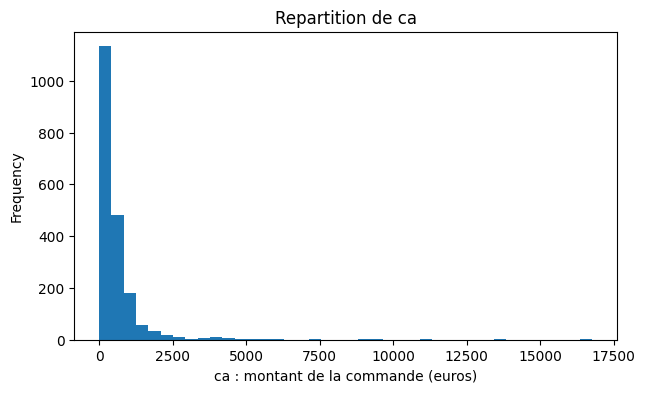

In [5]:
cmd["ca"].plot(kind="hist", bins=40, figsize=(7, 4))   ## la FORME
plt.title("Repartition de ca")
plt.xlabel("ca : montant de la commande (euros)")
plt.show()

Voilà la forme : un **tassement à gauche** et une **traîne qui s'étire loin à
droite**. Quelques commandes énormes (jusqu'à 16 775 €) tirent la moyenne vers
le haut sans déplacer la médiane d'un centime.

> 💡 **La règle.** Distribution symétrique : moyenne et médiane coïncident,
> prenez l'une ou l'autre. Distribution asymétrique — et **presque tout ce qui
> est en euros l'est** — la médiane décrit la situation typique, la moyenne
> décrit le total divisé par l'effectif. Affichez les deux.

## 2. Tout voir d'un coup : `describe()`

In [6]:
cmd["ca"].describe().round(2)   ## huit nombres, une distribution

,ca
count,1955.00
mean,589.73
std,918.41
min,1.45
25%,189.65
50%,355.89
75%,659.52
max,16774.72


Huit nombres, et la distribution est décrite :

| Ligne | Ce que ça dit ici |
|---|---|
| `count` | 1 955 commandes |
| `mean` | 589,73 € — la moyenne |
| `std` | 918,41 € — l'écart-type, voir plus bas |
| `min` | 1,45 € — la plus petite commande |
| `25%` | 189,65 € — un quart des commandes sont en dessous |
| `50%` | 355,89 € — la médiane |
| `75%` | 659,52 € — trois quarts sont en dessous |
| `max` | 16 774,72 € — la plus grosse |

### Les quantiles répondent aux questions de seuil

« À partir de quel montant une commande fait-elle partie des 10 % les plus
grosses ? » se lit directement :

In [7]:
# quantile(0.9) : 90 % des commandes sont EN DESSOUS de ce montant
print("seuil des 10 % du haut :", round(cmd["ca"].quantile(0.9), 2))
print("seuil des 10 % du bas  :", round(cmd["ca"].quantile(0.1), 2))

seuil des 10 % du haut : 1146.28
seuil des 10 % du bas  : 100.35


> ⚠️ **Le piège des quantiles :** ils s'expriment en **proportion**, entre 0
> et 1, jamais en pourcentage. La cellule suivante est volontairement fausse.

In [9]:
cmd["ca"].quantile(90)   ## erreur volontaire : 90 au lieu de 0.9

np.float64(1146.284)

Dernière ligne :

```
ValueError: percentiles should all be in the interval [0, 1]
```

Traduction : on attend une proportion entre 0 et 1. Les 10 % du haut, c'est
`quantile(0.9)`, pas `quantile(90)`. **Seule la dernière ligne d'une erreur
compte.**

### Mesurer la dispersion

Deux commandes à 350 € et 360 €, ou deux commandes à 10 € et 700 € : même
moyenne, situation très différente. La **dispersion** mesure cet étalement.

In [10]:
q1 = cmd["ca"].quantile(0.25)   ## un quart des commandes en dessous
q3 = cmd["ca"].quantile(0.75)   ## trois quarts en dessous

print("ecart-type          :", round(cmd["ca"].std(), 2))   ## fragile
print("ecart interquartile :", round(q3 - q1, 2))           ## robuste

ecart-type          : 918.41
ecart interquartile : 469.87


L'**écart-type** (`std`) mesure l'écart typique des observations à leur
moyenne. Il se lit dans la même unité que la variable — ici des euros.

**Regardez-le bien : 918 €, soit davantage que la moyenne elle-même.** Sur une
variable positive comme un montant, un écart-type supérieur à la moyenne est
un **indicateur** de dispersion très forte. C'est un signe, pas une preuve :
590 € reste la moyenne des 1 955 commandes, et elle garde son sens — c'est le
chiffre d'affaires total rapporté au nombre de commandes.

Ce que cet indicateur suggère, c'est autre chose : à ce niveau de dispersion,
la moyenne renseigne mal sur ce que dépense **une** commande prise au hasard.
La bonne réaction n'est pas de renoncer à la moyenne, c'est de ne pas la citer
seule — médiane et quantiles à côté.

L'**écart interquartile** (q3 − q1, ici 470 €) est sa version robuste : il
décrit l'étalement de la moitié centrale et ignore les extrêmes. Il ne bouge
pas si la plus grosse commande double.

## 3. Où est concentré le chiffre d'affaires ?

Une traîne à droite pose toujours la même question business : **quelle part du
total tient dans le haut du classement ?**

In [11]:
top = cmd["ca"].sort_values(ascending=False)   ## les plus grosses d'abord
n10 = int(0.10 * len(cmd))   ## les 10 % de commandes les plus grosses

part = 100 * top.head(n10).sum() / top.sum()   ## leur poids dans le total
print(n10, "commandes font", round(part, 1), "% du chiffre d'affaires")

195 commandes font 41.3 % du chiffre d'affaires


**195 commandes sur 1 955 font 41,3 % du chiffre d'affaires.**

Vous avez déjà croisé ce phénomène en séance 2.3 : deux clients irlandais
pesaient 22,7 % du CA. Ce n'était pas une anomalie isolée, c'est la façon dont
ce marché est fait.

Une moyenne **ne contient pas** cette information. Ce n'est pas qu'elle
l'effacerait ou la dissimulerait : elle répond à une autre question, « le total
rapporté à l'effectif », et la répartition du total n'entre nulle part dans ce
calcul. D'où la nécessité de calculer la concentration séparément — c'est une
question distincte, elle demande un chiffre distinct.

## 4. Décrire une variable qualitative

Tout ce qui précède suppose une variable **chiffrée** : on peut l'additionner,
la diviser, la classer. Un pays, un jour de la semaine, un segment de
clientèle, non. Ces variables-là sont **qualitatives** : elles ont des
**modalités**, pas des valeurs.

`describe()` le sait, et ne rend pas du tout les mêmes nombres :

In [12]:
cmd["jour"].describe()   ## la meme commande, sur une colonne de texte

,jour
count,1955
unique,6
top,jeudi
freq,441


Quatre lignes au lieu de huit, et pas une moyenne :

| | |
|---|---|
| `count` | 1 955 commandes |
| `unique` | **6** modalités différentes |
| `top` | `jeudi` — la modalité la plus fréquente : c'est le **mode** |
| `freq` | 441, l'effectif de ce mode |

> 📖 **Le mode.** Il répond à la question « quelle modalité revient le plus
> souvent ? », la seule notion de « centre » qui survive quand les valeurs ne se
> soustraient pas. On compte les observations de chaque modalité et on retient
> celle qui en a le plus. Il est fait pour les variables qualitatives : sur une
> variable continue comme `ca`, deux commandes tombent rarement au centime près
> sur le même montant, et il ne désigne alors presque rien. Il peut aussi être
> ambigu, quand deux modalités arrivent au coude à coude.
> [Wikipédia](https://fr.wikipedia.org/wiki/Mode_(statistiques))

*Nouveau :* `cmd["jour"].mode()` rend directement la modalité la plus
fréquente, sous forme de petite série — d'où le `[0]` pour en tirer la valeur.

Pour voir la distribution entière, on compte les modalités une à une. C'est le
`value_counts()` du bloc 2, et il trie déjà du plus fréquent au moins
fréquent :

In [13]:
cmd["jour"].value_counts()   ## l'effectif de chaque modalite, deja trie

,count
jour,
jeudi,441
mercredi,366
vendredi,334
mardi,318
lundi,307
dimanche,189


In [14]:
# normalize=True rend des parts entre 0 et 1 : x 100 pour des %
(100 * cmd["jour"].value_counts(normalize=True)).round(1)

,proportion
jour,
jeudi,22.6
mercredi,18.7
vendredi,17.1
mardi,16.3
lundi,15.7
dimanche,9.7


**Le jeudi porte 22,6 % des commandes, le dimanche 9,7 %.** Un tableau de
fréquences, c'est tout ce qu'une variable qualitative permet — et c'est déjà
beaucoup.

Regardez maintenant ce qui n'y est **pas** : six modalités pour sept jours de
la semaine. **Il n'y a pas une seule commande le samedi.** Une modalité absente
ne se voit dans aucun tableau de fréquences — il faut savoir ce qu'on attend
pour remarquer ce qui manque.

> ⚠️ **Ni moyenne, ni écart-type, ni écart interquartile ici.** Ces trois
> mesures reposent sur des **distances** entre valeurs : `(valeur − moyenne)²`
> ne veut dire quelque chose que si soustraire deux valeurs a un sens. « jeudi
> moins lundi » n'en a aucun, « France moins Belgique » non plus. La médiane
> demande moins — un **ordre** — mais des pays n'en ont pas davantage.
>
> Le danger n'est pas l'erreur bruyante : sur du texte, pandas refuse. C'est le
> jour où ces modalités arrivent **codées en 1, 2, 3** dans un fichier. La
> moyenne vaudra 3,8 et ne voudra rien dire.

### La dispersion d'une variable qualitative

Elle existe, mais elle ne se mesure pas en euros : elle se lit dans le
**nombre de modalités** et dans le **poids de la première**.

In [15]:
parts = 100 * cmd["pays"].value_counts(normalize=True)

print("modalites     :", cmd["pays"].nunique())   ## combien de pays
print("part du n.1   :", round(parts.iloc[0], 1), "%")   ## le plus frequent
print("part du top 3 :", round(parts.head(3).sum(), 1), "%")

modalites     : 23
part du n.1   : 40.8 %
part du top 3 : 66.9 %


**23 pays, et le premier en pèse 40,8 % à lui seul ; les trois premiers,
66,9 %.** C'est exactement la concentration de la section 3, transposée au
qualitatif : beaucoup de modalités, mais quelques-unes portent l'essentiel.

Deux variables qualitatives se comparent ainsi : `jour` a 6 modalités dont la
première pèse 22,6 % — c'est une variable **étalée**. `pays` en a 23 dont la
première pèse 40,8 % — c'est une variable **concentrée**.

> 💡 **Une exception à connaître : les qualitatives _ordonnées_.** Un segment
> « occasionnel < standard < premium », une note de 1 à 5 : les modalités ont
> un ordre. La médiane redevient calculable — la moyenne, non. Une moyenne de
> 3,4 sur une échelle de satisfaction se lit partout, et ne veut toujours rien
> dire.

## 5. Comparer des groupes sans se faire piéger

Même question, pays par pays. Notez l'ordre des colonnes : **`count` d'abord**.

### Regrouper les observations avec `groupby`

`groupby` permet de **regrouper les lignes qui partagent une même valeur**, puis d'effectuer le même calcul séparément dans chaque groupe.

Par exemple, au lieu de calculer une seule moyenne de chiffre d'affaires pour toutes les commandes, on peut calculer **une moyenne pour chaque pays** :

```python
cmd.groupby("pays")["ca"].mean()
```

La commande se lit de gauche à droite :

1. `cmd.groupby("pays")` : former un groupe pour chaque pays ;
2. `["ca"]` : choisir la variable que l'on veut résumer ;
3. `.mean()` : calculer la moyenne de `ca` séparément dans chacun de ces groupes.

Le résultat contient donc **une valeur par pays**, et non plus une seule valeur pour l'ensemble du fichier.

La structure générale est :

```python
df.groupby("variable_de_groupe")["variable_a_resumer"].statistique()
```

In [16]:
# une moyenne de ca pour chaque pays
cmd.groupby("pays")["ca"].mean().head()

,ca
pays,
Allemagne,540.291786
Australie,398.246667
Autre,1172.274118
Autriche,626.886429
Belgique,446.698333


### Calculer plusieurs indicateurs par groupe

Après un `groupby`, on n'est pas limité à une seule statistique.

Avec `.agg()`, on peut demander plusieurs indicateurs en même temps :

```python
cmd.groupby("pays")["ca"].agg(["count", "mean", "median"])
```

Pour chaque pays, pandas calcule alors :

- `count` : le nombre de commandes ;
- `mean` : le chiffre d'affaires moyen ;
- `median` : le chiffre d'affaires médian.

On obtient donc un tableau avec **une ligne par groupe** et **une colonne par statistique demandée**.

L'effectif (`count`) est important : une moyenne calculée sur 12 commandes ne se commente pas de la même façon qu'une moyenne calculée sur 800 commandes.

In [17]:
# count EN PREMIER : on ne commente pas un groupe sans son effectif
parpays = cmd.groupby("pays")["ca"].agg(["count", "mean", "median"])

parpays.query("count >= 20").sort_values("mean", ascending=False).round(2)

,count,mean,median
pays,,,
Suede,25,1409.27,486.10
Autre,34,1172.27,727.61
Suisse,47,1044.42,667.03
Irlande,256,1020.33,657.62
Portugal,28,662.57,530.92
Espagne,64,603.43,379.64
Allemagne,252,540.29,378.85
France,253,529.58,361.35
Belgique,72,446.70,348.96


Trois lectures :

- **La Suède : 1 409 € de moyenne, 486 € de médiane.** L'écart le plus violent
  du tableau, sur 25 commandes. Une ou deux commandes exceptionnelles suffisent
  à produire ce chiffre.
- **L'Irlande : 1 020 € de moyenne** — et vous savez depuis la séance 2.3
  qu'elle n'a que **deux clients**.
- **Le Royaume-Uni : moyenne 394 €, médiane 301 €.** L'écart le plus faible :
  c'est le marché le plus régulier, celui sur lequel une moyenne veut dire
  quelque chose.

> ⚠️ **Le filtre `count >= 20` n'est pas de la coquetterie.** Sans lui, le
> Japon arrive en tête du classement avec 2 178 € de moyenne… sur 12 commandes.
> Regardez toujours l'effectif avant de commenter un groupe.

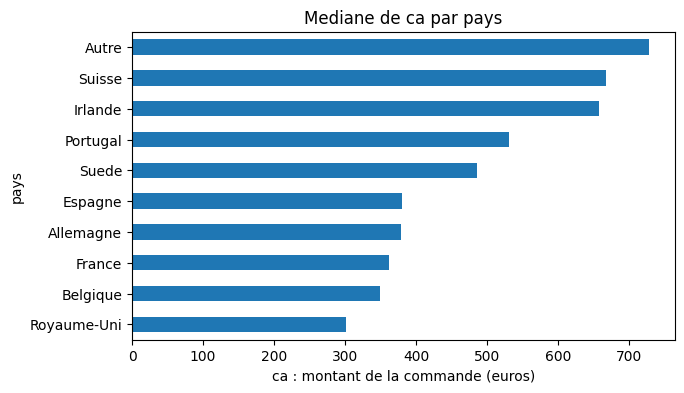

In [18]:
# Trier avant de tracer : un graphique en barres non trie est illisible
parpays.query("count >= 20").sort_values("median")["median"].plot(
    kind="barh", figsize=(7, 4))
plt.title("Mediane de ca par pays")
plt.xlabel("ca : montant de la commande (euros)")
plt.show()

---

## Ce que vous savez faire maintenant

| Vous voulez... | La commande |
|---|---|
| tout d'un coup | `df["ca"].describe()` |
| le centre, version fragile | `df["ca"].mean()` |
| le centre, version robuste | `df["ca"].median()` |
| un seuil, ici les 10 % du haut | `df["ca"].quantile(0.9)` |
| la dispersion, version fragile | `df["ca"].std()` |
| la dispersion, version robuste | `q3 - q1` |
| la forme | `df["ca"].plot(kind="hist", bins=40)` |
| décrire une colonne qualitative | `df["jour"].describe()` — count, unique, top, freq |
| la modalité la plus fréquente | `df["jour"].mode()[0]`, le **mode** |
| le tableau de fréquences | `df["jour"].value_counts()` |
| ...en parts plutôt qu'en effectifs | `df["jour"].value_counts(normalize=True)` |
| calculer une statistique par groupe | `df.groupby("pays")["ca"].mean()` |
| calculer plusieurs statistiques par groupe | `df.groupby("pays")["ca"].agg(["count", "mean", "median"])` |
| combien de modalités | `df["jour"].nunique()` |

## Les quatre réflexes de la séance

1. **Toujours afficher la médiane à côté de la moyenne.** L'écart entre les
   deux mesure l'asymétrie. Ici : 590 € contre 356 €, et seulement 29 % des
   commandes dépassent la « moyenne ».

2. **Avec `groupby`, pensez : regrouper → choisir la variable → calculer.**
   Par exemple, `df.groupby("pays")["ca"].mean()` calcule une moyenne de `ca`
   séparément pour chaque pays. Avec `.agg()`, on peut calculer plusieurs
   indicateurs en une seule fois.

3. **Sur une variable qualitative, ni moyenne ni écart-type.** Le mode et un
   tableau de fréquences, rien de plus. Le jour où les modalités arrivent
   codées en 1, 2, 3, la moyenne se calculera sans broncher et ne voudra
   toujours rien dire.

4. **Regardez toujours l'effectif avant de comparer des groupes.** Une moyenne
   calculée sur 12 commandes n'a pas la même solidité descriptive qu'une
   moyenne calculée sur plusieurs centaines de commandes. C'est pourquoi
   `count` est souvent utile à côté de `mean` et `median`.